
# Exercice 4 — Régression sur le jeu de données fourni 

Les données viennent de `FTML/project/data/regression/` (recopiées dans `data/`). Le train et le test font chacun 200 points en dimension 200.

$n = d = 200$, et la matrice de design est de rang plein. Autrement dit l'OLS a autant de paramètres que de points : il peut passer exactement par toutes les données d'entraînement. La cellule suivante le vérifie, et le résultat en test est parlant.


In [1]:
# On charge les données, puis on regarde l'OLS sans régularisation comme référence. Comme n = d, on s'attend à un R2 de train parfait mais un R2 de test très mauvais (interpolation du bruit).

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, KFold


def load_data(data_dir: Path):
    """
    Charge les matrices de design et les cibles d'entraînement / test.

    Paramètres :
        data_dir (Path) : dossier contenant X_train/y_train/X_test/y_test .npy.

    Retour :
        tuple : X_train (n, d), y_train (n,), X_test (n, d), y_test (n,).
    """
    X_train = np.load(data_dir / "X_train.npy")
    y_train = np.load(data_dir / "y_train.npy").ravel()
    X_test = np.load(data_dir / "X_test.npy")
    y_test = np.load(data_dir / "y_test.npy").ravel()
    return X_train, y_train, X_test, y_test


# données recopiées depuis FTML/project/data/regression/
X_train, y_train, X_test, y_test = load_data(Path("data"))
n, d = X_train.shape
print(f"entraînement : n = {n}, d = {d}")
print(f"rang de X_train : {np.linalg.matrix_rank(X_train)} (rang plein)")
print(f"features : valeurs dans [{X_train.min():.3f}, {X_train.max():.3f}], "
      f"écarts-types de colonnes de {X_train.std(0).min():.2f} à {X_train.std(0).max():.2f}")

# estimateur de référence : OLS, sans aucune régularisation
ols = LinearRegression().fit(X_train, y_train)
print("\nOLS (référence)")
print(f"    R2 train : {ols.score(X_train, y_train):.4f}")
print(f"    R2 test  : {ols.score(X_test, y_test):.4f}")

entraînement : n = 200, d = 200
rang de X_train : 200 (rang plein)
features : valeurs dans [0.000, 1.000], écarts-types de colonnes de 0.26 à 0.32

OLS (référence)
    R2 train : 1.0000
    R2 test  : -9.9188



Voilà le surapprentissage dans les grandes largeurs : $R^2 = 1$ en train, mais $R^2 = -9.92$ en test, c'est-à-dire pire qu'un modèle qui prédirait bêtement la moyenne. L'OLS a appris le bruit par cœur. Il faut régulariser.

Maintenant, je compare deux estimateurs linéaires régularisés, Ridge et Lasso, qui font des hypothèses différentes sur les coefficients. Le protocole est le même pour les deux, et surtout il ne laisse rien fuir du test :

* le $\alpha$ de régularisation est choisi par validation croisée à 5 plis, uniquement sur le train (50 valeurs en échelle log, $\alpha \in [10^{-3}, 10^3]$ pour Ridge et $[10^{-4}, 1]$ pour Lasso, score $R^2$),
* le test ne sert qu'une fois, à la fin, pour le score final.

Deux réglages pratiques : je monte `max_iter` à $10^5$ pour le Lasso, sinon son solveur ne converge pas pour les petits $\alpha$. Et je ne standardise pas les colonnes : la cellule précédente confirme qu'elles sont déjà dans $[0,1]$ avec des écarts-types comparables (0.26 à 0.32). C'est la seule différence de protocole avec l'exercice 5, dont les features sont sur des échelles très différentes et imposent un StandardScaler.

Côté solveurs : l'OLS et Ridge se résolvent en forme close (moindres carrés via SVD pour `LinearRegression`, système linéaire de type Cholesky pour `Ridge`), il n'y a donc ni itération ni réglage de convergence pour eux. Le Lasso n'a pas de forme close à cause de la pénalité L1 : scikit-learn le résout par descente par coordonnées, itérative, d'où le réglage de `max_iter` mentionné ci-dessus (aucun avertissement de convergence levé).

In [2]:
def select_by_cross_validation(model, param_grid):
    """
    Choisit le paramètre de régularisation par validation croisée à 5 plis, sur
    le seul jeu d'entraînement.

    Paramètres :
        model : un régresseur scikit-learn non ajusté (ex. Ridge, Lasso).
        param_grid (dict) : grille de valeurs d'hyperparamètres à explorer.

    Retour :
        GridSearchCV : l'objet de recherche ajusté (meilleur estimateur + scores).
    """
    cross_validation = KFold(n_splits=5, shuffle=True, random_state=0)
    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        cv=cross_validation,
        scoring="r2",
    )
    grid_search.fit(X_train, y_train)
    return grid_search


models = {
    "Ridge": (Ridge(), {"alpha": np.logspace(-3, 3, 50)}),
    "Lasso": (Lasso(max_iter=100_000), {"alpha": np.logspace(-4, 0, 50)}),
}

cv_curves = {}
searches = {}
for name, (model, param_grid) in models.items():
    grid_search = select_by_cross_validation(model, param_grid)
    best_alpha = grid_search.best_params_["alpha"]
    print(f"{name}")
    print(f"    meilleur alpha (CV 5 plis) : {best_alpha:.2e}")
    print(f"    R2 validation croisée      : {grid_search.best_score_:.4f}")
    print(f"    R2 train                   : {grid_search.score(X_train, y_train):.4f}")
    print(f"    R2 test                    : {grid_search.score(X_test, y_test):.4f}")
    if name == "Lasso":
        n_nonzero = np.sum(grid_search.best_estimator_.coef_ != 0)
        print(f"    coefficients non nuls      : {n_nonzero}/{d}")
    print()
    searches[name] = grid_search
    cv_curves[name] = (
        param_grid["alpha"],
        grid_search.cv_results_["mean_test_score"],
    )

Ridge
    meilleur alpha (CV 5 plis) : 1.15e+00
    R2 validation croisée      : 0.6241
    R2 train                   : 0.9863
    R2 test                    : 0.7125



Lasso
    meilleur alpha (CV 5 plis) : 5.18e-03
    R2 validation croisée      : 0.9361
    R2 train                   : 0.9630
    R2 test                    : 0.9231
    coefficients non nuls      : 44/200



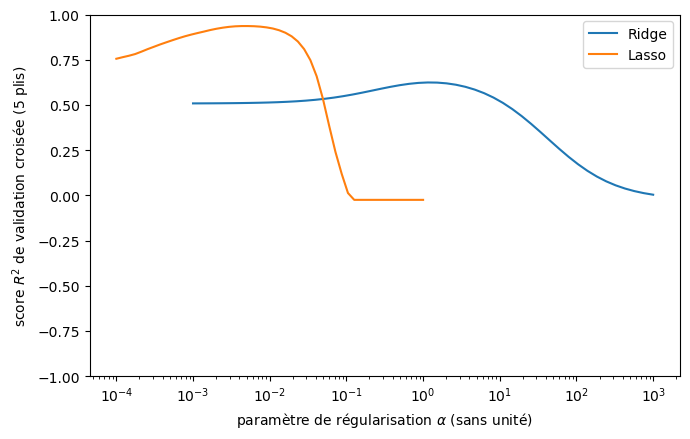

In [3]:
# score de validation croisée en fonction de alpha, pour situer l'optimum retenu
plt.figure(figsize=(7, 4.5))
for name, (alphas, scores) in cv_curves.items():
    plt.semilogx(alphas, scores, label=name)
plt.xlabel(r"paramètre de régularisation $\alpha$ (sans unité)")
plt.ylabel("score $R^2$ de validation croisée (5 plis)")
plt.ylim(-1, 1)
plt.legend()
plt.tight_layout()
plt.show()

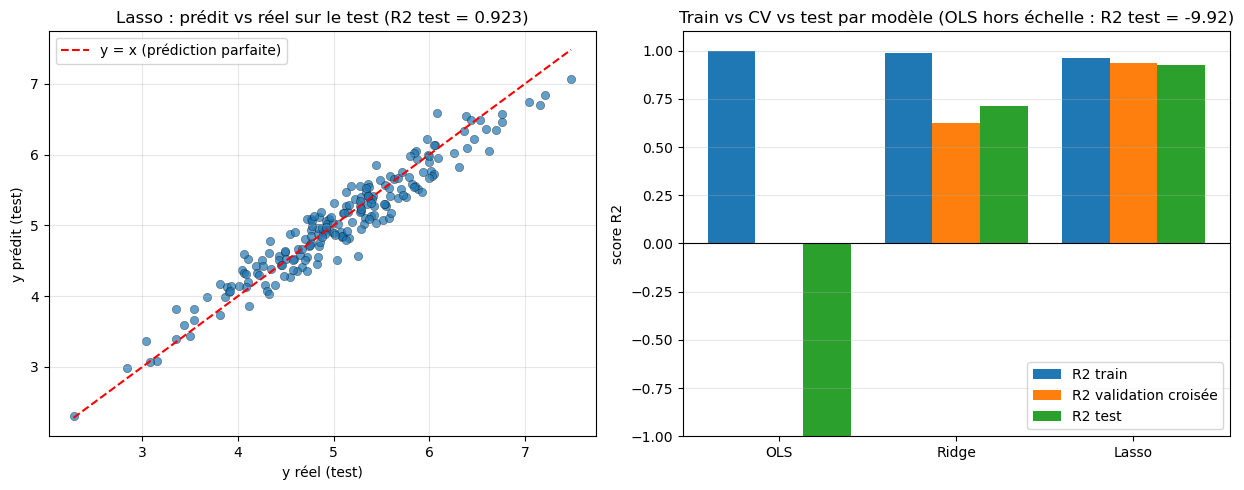

In [4]:
# diagnostic sur le test : prédit vs réel pour le Lasso retenu, et comparaison
# train / CV / test des trois modèles (OLS de référence inclus)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))

best = searches["Lasso"].best_estimator_
y_pred = best.predict(X_test)
axes[0].scatter(y_test, y_pred, alpha=0.7, edgecolor="k", linewidth=0.3)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, "r--", label="y = x (prédiction parfaite)")
axes[0].set_xlabel("y réel (test)")
axes[0].set_ylabel("y prédit (test)")
axes[0].set_title(f"Lasso : prédit vs réel sur le test "
                  f"(R2 test = {searches['Lasso'].score(X_test, y_test):.3f})")
axes[0].legend()
axes[0].grid(alpha=0.3)

noms = ["OLS", "Ridge", "Lasso"]
r2_train = [ols.score(X_train, y_train),
            searches["Ridge"].score(X_train, y_train),
            searches["Lasso"].score(X_train, y_train)]
r2_cv = [np.nan, searches["Ridge"].best_score_, searches["Lasso"].best_score_]
r2_test = [ols.score(X_test, y_test),
           searches["Ridge"].score(X_test, y_test),
           searches["Lasso"].score(X_test, y_test)]
xpos = np.arange(len(noms))
largeur = 0.27
axes[1].bar(xpos - largeur, r2_train, largeur, label="R2 train")
axes[1].bar(xpos, r2_cv, largeur, label="R2 validation croisée")
axes[1].bar(xpos + largeur, r2_test, largeur, label="R2 test")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xticks(xpos, noms)
axes[1].set_ylabel("score R2")
axes[1].set_title("Train vs CV vs test par modèle (OLS hors échelle : R2 test = -9.92)")
axes[1].set_ylim(-1, 1.1)
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

## Vérifier ce qu'on avance : parcimonie, Ridge et cohérence train/test

Deux affirmations méritent d'être prouvées plutôt qu'assénées, et une troisième vérification fait le lien avec l'exercice 5.

- La parcimonie : le Lasso ne garde que 44 coefficients, mais est-ce une vraie structure du problème ou un artefact d'un découpage ? On regarde la stabilité de la sélection sur les cinq plis.
- L'hypothèse « Ridge gagnerait avec une sélection de variables » : on la teste directement en donnant à Ridge les seules features retenues par le Lasso.
- La cohérence train/test : l'exercice 5 a révélé un décalage entre train et test sur le jeu de classification. On vérifie qu'ici, au contraire, train et test sont cohérents, ce qui explique qu'on atteigne le plancher de Bayes.

Lasso : 44/200 features retenues sur tout le train
  noyau stable : 18 features dans les 5 plis, 108 jamais sélectionnées

Ridge sur les 200 features           : R2 test = 0.7125
Ridge sur les 44 features du Lasso : R2 test = 0.9033
Lasso (référence)                    : R2 test = 0.9231



AUC classifieur train-vs-test : 0.5550 (0.5 = indistinguables)
Lasso : CV = 0.9361, test = 0.9231, Bayes annoncé ~ 0.92


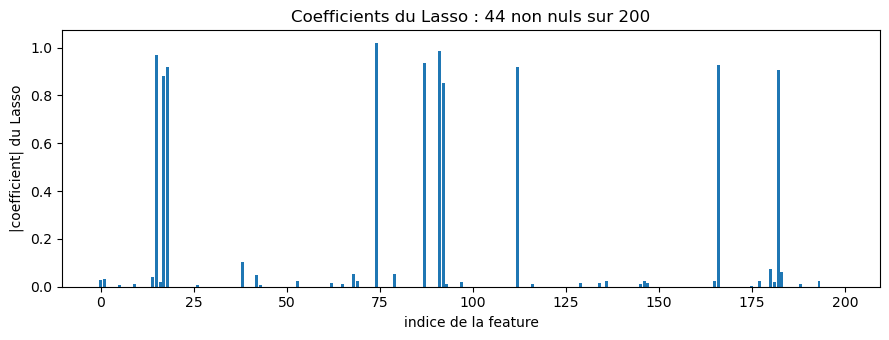

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import r2_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

lasso_best = searches["Lasso"].best_estimator_
alpha_lasso = searches["Lasso"].best_params_["alpha"]
feats = np.where(np.abs(lasso_best.coef_) > 1e-8)[0]

# 1. stabilité de la sélection : combien de features reviennent sur les 5 plis d'entraînement
cv5 = KFold(n_splits=5, shuffle=True, random_state=0)
counts = np.zeros(X_train.shape[1], dtype=int)
for tr_idx, _ in cv5.split(X_train):
    m = Lasso(alpha=alpha_lasso, max_iter=100000).fit(X_train[tr_idx], y_train[tr_idx])
    counts += np.abs(m.coef_) > 1e-8
print(f"Lasso : {len(feats)}/200 features retenues sur tout le train")
print(f"  noyau stable : {(counts == 5).sum()} features dans les 5 plis, {(counts == 0).sum()} jamais sélectionnées")

# 2. hypothèse Ridge + sélection : Ridge sur les seules features du Lasso rattrape-t-il le Lasso ?
ridge_sel = GridSearchCV(Ridge(), {"alpha": np.logspace(-3, 3, 50)}, cv=cv5, scoring="r2").fit(X_train[:, feats], y_train)
print(f"\nRidge sur les 200 features           : R2 test = {searches['Ridge'].score(X_test, y_test):.4f}")
print(f"Ridge sur les {len(feats)} features du Lasso : R2 test = {r2_score(y_test, ridge_sel.predict(X_test[:, feats])):.4f}")
print(f"Lasso (référence)                    : R2 test = {searches['Lasso'].score(X_test, y_test):.4f}")

# 3. cohérence train/test (miroir de l'exercice 5) : un classifieur distingue-t-il train et test ?
Xd = np.vstack([X_train, X_test])
yd = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
auc = cross_val_score(RandomForestClassifier(200, random_state=0), Xd, yd, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc").mean()
print(f"\nAUC classifieur train-vs-test : {auc:.4f} (0.5 = indistinguables)")
print(f"Lasso : CV = {searches['Lasso'].best_score_:.4f}, test = {searches['Lasso'].score(X_test, y_test):.4f}, Bayes annoncé ~ 0.92")

# graphe des coefficients du Lasso : la parcimonie se voit d'un coup d'oeil
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(len(lasso_best.coef_)), np.abs(lasso_best.coef_), color="tab:blue")
ax.set_xlabel("indice de la feature")
ax.set_ylabel("|coefficient| du Lasso")
ax.set_title(f"Coefficients du Lasso : {len(feats)} non nuls sur 200")
fig.tight_layout()
plt.show()

Lecture. La sélection est stable : un noyau de features revient dans tous les plis et plus de la moitié des variables ne sont jamais retenues, la parcimonie est donc une propriété du problème, pas un hasard de découpage. L'hypothèse sur Ridge se confirme : restreint aux features du Lasso, Ridge bondit de 0.71 à 0.90 et rejoint presque le Lasso, ce qui montre que sa faiblesse venait des variables de bruit et non de la pénalité L2 en soi, le petit reste d'écart étant l'avantage propre de la sélection intégrée du Lasso.

Enfin, contrairement au jeu de classification de l'exercice 5 où train et test divergent nettement, ici ils sont cohérents : un classifieur ne les sépare pas significativement — AUC de 0.56, ce qui reste dans la fluctuation attendue du hasard à cette taille d'échantillon (400 points en dimension 200) — et le score de validation croisée du Lasso colle à son score de test. C'est précisément cette cohérence qui permet d'atteindre le plancher de Bayes annoncé, là où l'exercice 5 en était empêché.


## Résultats et conclusion :

| méthode | $\alpha$ retenu | $R^2$ CV (5 plis) | $R^2$ train | $R^2$ test |
|---|---|---|---|---|
| OLS | - | - | 1.0000 | −9.92 |
| Ridge | 1.15 | 0.6241 | 0.9863 | 0.7125 |
| Lasso | $5.18\times10^{-3}$ | 0.9361 | 0.9630 | **0.9231** |

Ce que je retiens :

* Le Lasso arrive à $R^2 = 0.9231$ en test, au-dessus de l'objectif de 0.88 et au niveau du prédicteur de Bayes annoncé dans l'énoncé ($\approx 0.92$). Il ne reste donc pas grand-chose à gratter, le gros de l'erreur restante est irréductible.
* Le Lasso retenu ne garde que 44 coefficients sur 200, avec un noyau stable sur les plis (vérifié plus haut) : le problème est réellement parcimonieux, ce qui explique pourquoi le Lasso (0.9231) écrase Ridge (0.7125) sur ce jeu où $n = d$. La section précédente confirme que c'est bien la sélection qui compte, pas la forme de la pénalité : Ridge restreint aux 44 features du Lasso remonte à 0.90.
* La validation croisée a vu juste : le score CV du Lasso (0.9361, sur le train) est très proche de son score de test (0.9231), donc le choix de $\alpha$ n'a pas surappris sur les plis.

Quand $n = d$, régulariser n'est pas optionnel, et la bonne hypothèse ici est la parcimonie, que la section de vérification établit au lieu de la supposer. Le Lasso, avec un $\alpha$ choisi par validation croisée à 5 plis sur le seul train, passe l'objectif avec un $R^2$ de test de 0.9231, au niveau du plancher de Bayes, cohérence train/test à l'appui.
